# Лабораторная работа №8: Доверительные интервалы для вероятности успеха (биномиальная модель)

**Задание.**
1. Реализовать точный интервал Клоппера–Пирсона (бисекция по биномиальному хвосту) и сравнить с аппроксимациями: `statsmodels.stats.proportion.confint`, Wald, Wilson, Agresti–Coull, Jeffreys.
2. Построить ширину ДИ в зависимости от числа успехов $m = 0, 1, \ldots, n$ при $n = 100$, $Q = 0{,}95$.
3. Проверить номинальную $Q = 0{,}95$ против эмпирической $Q^*$: для $n \in \{10, 50, 100, 150, 200, 500\}$, $p \in \{0{,}1,\, 0{,}5,\, 0{,}9\}$, $N = 10^3$ симуляций; построить $Q^*$ от $n$ с доверительными полосами для самой $Q^*$.


## Теория

### Постановка

Наблюдаем $m$ успехов в $n$ независимых испытаниях Бернулли с неизвестной вероятностью успеха $p$. Требуется построить двусторонний доверительный интервал $(L, U)$ для $p$ с доверительной вероятностью $Q$, т.е. чтобы
$$
P_p(L < p < U) \ge Q .
$$
Здесь $p$ — фиксированный параметр, а $(L, U)$ — случайные величины, зависящие от $m$.

Обозначим $\alpha = 1 - Q$ (уровень значимости двустороннего теста).

### Точный интервал Клоппера–Пирсона (Clopper–Pearson)

Идея: для фиксированного $p$ функция
$$
\bar F_p(m) = \sum_{k=m}^{n} \binom{n}{k} p^k (1-p)^{n-k} = P(X \ge m), \quad X \sim \mathrm{Bin}(n, p),
$$
монотонно убывает по $p$ при фиксированном $m$. Значит, уравнение $\bar F_p(m) = \alpha/2$ имеет единственный корень по $p$; этот корень берём как **нижнюю** границу $L$ (кроме $m=0$, где $L=0$).

Аналогично, $F_p(m) = \sum_{k=0}^{m} \binom{n}{k} p^k (1-p)^{n-k}$ монотонно возрастает по $p$, и уравнение $F_p(m) = \alpha/2$ даёт **верхнюю** границу $U$ (кроме $m=n$, где $U=1$).

Формально:
- если $m = 0$, то $L = 0$; иначе $L$ — решение
  $$
  \sum_{k=m}^{n} \binom{n}{k} L^k (1-L)^{n-k} = \frac{\alpha}{2}.
  $$
- если $m = n$, то $U = 1$; иначе $U$ — решение
  $$
  \sum_{k=0}^{m} \binom{n}{k} U^k (1-U)^{n-k} = \frac{\alpha}{2}.
  $$

#### Связь с бета-распределением

Из тождества для неполной бета-функции и биномиального хвоста:
$$
\sum_{k=a}^{n} \binom{n}{k} p^k (1-p)^{n-k} = I_p(a,\, n-a+1),
$$
где $I_p(\cdot,\cdot)$ — регуляризованная неполная бета-функция. Отсюда при $m > 0$
$$
\frac{\alpha}{2} = I_L(m,\, n-m+1) \quad\Longleftrightarrow\quad L = F^{-1}_{\mathrm{Beta}(m,\, n-m+1)}\!\left(\frac{\alpha}{2}\right),
$$
а при $m < n$
$$
\frac{\alpha}{2} = I_U(m+1,\, n-m) \quad\Longleftrightarrow\quad U = F^{-1}_{\mathrm{Beta}(m+1,\, n-m)}\!\left(1 - \frac{\alpha}{2}\right).
$$

В `scipy`: `beta.ppf(alpha/2, m, n-m+1)` и `beta.ppf(1-alpha/2, m+1, n-m)`.

Интервал **консервативен** (точное покрытие $\ge Q$), что и проверяется в п. 3.

#### Бисекция

Для проверки реализуем поиск $L$ бисекцией на $[0, 1]$: на каждом шаге вычисляем $\bar F_p(m)$ через `binom.sf(m-1, n, p)` (или сумму) и сравниваем с $\alpha/2$. Верхнюю границу ищем через `binom.cdf(m, n, p) = \alpha/2$. Сходимость — линейная, за $\sim 50$ итераций точность $\sim 10^{-15}$.

### Асимптотические и аппроксимативные методы

Пусть $\hat p = m/n$, $z = z_{(1+Q)/2} = \Phi^{-1}\bigl(\frac{1+Q}{2}\bigr)$.

**Wald** (наивная нормальная аппроксимация):
$$
L_W = \hat p - z\sqrt{\frac{\hat p(1-\hat p)}{n}}, \qquad
U_W = \hat p + z\sqrt{\frac{\hat p(1-\hat p)}{n}}.
$$
Плохо работает при малых $n$ и крайних $p$ (покрытие может быть $< Q$).

**Wilson (score)**:
$$
\tilde p = \frac{\hat p + z^2/(2n)}{1 + z^2/n}, \qquad
\Delta = \frac{z}{1+z^2/n}\sqrt{\frac{\hat p(1-\hat p)}{n} + \frac{z^2}{4n^2}},
$$
$L = \tilde p - \Delta$, $U = \tilde p + \Delta$. Обычно ближе к номинальному $Q$, чем Wald.

**Agresti–Coull**: «псевдосчёт» $m' = m + z^2/2$, $n' = n + z^2$, $\hat p' = m'/n'$, затем Wald с $(\hat p', n')$.

**Jeffreys** (байесовский равновероятностный при априори $\mathrm{Beta}(1/2, 1/2)$):
$$
L_J = F^{-1}_{\mathrm{Beta}(m+1/2,\, n-m+1/2)}(\alpha/2), \qquad
U_J = F^{-1}_{\mathrm{Beta}(m+1/2,\, n-m+1/2)}(1-\alpha/2).
$$

### Эмпирическое покрытие $Q^*$

Для фиксированных $(n, p)$ генерируем $N$ раз $m_j \sim \mathrm{Bin}(n, p)$, строим ДИ $(L_j, U_j)$ и считаем
$$
Q^* = \frac{1}{N}\sum_{j=1}^{N} \mathbf{1}\{L_j < p < U_j\}.
$$
Если метод корректен, $Q^* \approx Q$ (погрешность порядка $\sqrt{Q(1-Q)/N} \approx 0{,}007$ при $N=1000$).

Для интервала вокруг самой $Q^*$ используем точный биномиальный ДИ Клоппера–Пирсона по $K$ «успехов» (накрытий) из $N$ испытаний.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import comb
from statsmodels.stats.proportion import proportion_confint

SEED = 42
Q = 0.95
ALPHA = 1 - Q
N_SIM = 10**3
rng = np.random.default_rng(SEED)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10

Z = stats.norm.ppf((1 + Q) / 2)

METHODS = ['Clopper-Pearson', 'Wald', 'Wilson', 'Agresti-Coull', 'Jeffreys', 'statsmodels-wilson']
COLORS = {
    'Clopper-Pearson': 'black',
    'Wald': 'tab:red',
    'Wilson': 'tab:blue',
    'Agresti-Coull': 'tab:green',
    'Jeffreys': 'tab:purple',
    'statsmodels-wilson': 'tab:orange',
}


## 1. Точный Клоппер–Пирсон: бисекция и бета-квантили

In [2]:
def binom_upper_tail(n, m, p):
    """P(X >= m), X ~ Bin(n, p)."""
    return stats.binom.sf(m - 1, n, p)


def binom_lower_tail(n, m, p):
    return stats.binom.cdf(m, n, p)


def clopper_pearson_bisection(n, m, alpha=ALPHA, tol=1e-12, maxiter=80):
    """Точный CP: бисекция по биномиальным хвостам."""
    m = int(m)
    if m == 0:
        lo = 0.0
    else:
        lo, hi = 0.0, 1.0
        target = alpha / 2
        for _ in range(maxiter):
            mid = (lo + hi) / 2
            if binom_upper_tail(n, m, mid) > target:
                hi = mid
            else:
                lo = mid
            if hi - lo < tol:
                break
        lo = (lo + hi) / 2

    if m == n:
        hi = 1.0
    else:
        lo_b, hi_b = 0.0, 1.0
        target = alpha / 2
        for _ in range(maxiter):
            mid = (lo_b + hi_b) / 2
            if binom_lower_tail(n, m, mid) < target:
                hi_b = mid
            else:
                lo_b = mid
            if hi_b - lo_b < tol:
                break
        hi = (lo_b + hi_b) / 2

    return lo, hi


def clopper_pearson_beta(n, m, alpha=ALPHA):
    m = int(m)
    lo = 0.0 if m == 0 else stats.beta.ppf(alpha / 2, m, n - m + 1)
    hi = 1.0 if m == n else stats.beta.ppf(1 - alpha / 2, m + 1, n - m)
    return lo, hi


def wald_ci(n, m, alpha=ALPHA):
    ph = m / n
    se = np.sqrt(ph * (1 - ph) / n)
    half = Z * se
    return ph - half, ph + half


def wilson_ci(n, m, alpha=ALPHA):
    ph = m / n
    z2 = Z ** 2
    denom = 1 + z2 / n
    center = (ph + z2 / (2 * n)) / denom
    margin = Z / denom * np.sqrt(ph * (1 - ph) / n + z2 / (4 * n ** 2))
    return center - margin, center + margin


def agresti_coull_ci(n, m, alpha=ALPHA):
    m_a = m + z2 / 2
    n_a = n + z2
    ph = m_a / n_a
    se = np.sqrt(ph * (1 - ph) / n_a)
    half = Z * se
    return ph - half, ph + half


def jeffreys_ci(n, m, alpha=ALPHA):
    a, b = m + 0.5, n - m + 0.5
    return stats.beta.ppf(alpha / 2, a, b), stats.beta.ppf(1 - alpha / 2, a, b)


z2 = Z ** 2


def ci_pair(n, m, method, alpha=ALPHA):
    if method == 'Clopper-Pearson':
        return clopper_pearson_beta(n, m, alpha)
    if method == 'Wald':
        return wald_ci(n, m, alpha)
    if method == 'Wilson':
        return wilson_ci(n, m, alpha)
    if method == 'Agresti-Coull':
        return agresti_coull_ci(n, m, alpha)
    if method == 'Jeffreys':
        return jeffreys_ci(n, m, alpha)
    if method == 'statsmodels-wilson':
        lo, hi = proportion_confint(m, n, alpha=alpha, method='wilson')
        return float(lo), float(hi)
    raise ValueError(method)


In [3]:
# Сверка бисекции и beta.ppf
test_pairs = [(10, 0), (10, 3), (10, 10), (50, 5), (50, 25), (100, 7), (100, 93), (200, 100)]
rows = []
for n, m in test_pairs:
    lo_b, hi_b = clopper_pearson_bisection(n, m)
    lo_p, hi_p = clopper_pearson_beta(n, m)
    rows.append({
        'n': n, 'm': m,
        'L_bisect': lo_b, 'L_beta': lo_p, 'dL': abs(lo_b - lo_p),
        'U_bisect': hi_b, 'U_beta': hi_p, 'dU': abs(hi_b - hi_p),
    })

print('Макс. |разница| L между бисекцией и beta:', max(r['dL'] for r in rows))
print('Макс. |разница| U между бисекцией и beta:', max(r['dU'] for r in rows))
print()
for r in rows:
    print(f"n={r['n']:3d} m={r['m']:3d}: dL={r['dL']:.2e}, dU={r['dU']:.2e}")

# Сравнение со statsmodels (method='binom_test' / beta для CP)
print('\nClopper–Pearson vs statsmodels (method=\'beta\'):')
for n, m in [(25, 7), (100, 42)]:
    lo, hi = clopper_pearson_beta(n, m)
    lo_s, hi_s = proportion_confint(m, n, alpha=ALPHA, method='beta')
    print(f"  n={n}, m={m}: ours ({lo:.6f}, {hi:.6f}) | statsmodels ({lo_s:.6f}, {hi_s:.6f})")


Макс. |разница| L между бисекцией и beta: 4.498346140024978e-13
Макс. |разница| U между бисекцией и beta: 4.490852134608758e-13

n= 10 m=  0: dL=0.00e+00, dU=4.49e-13
n= 10 m=  3: dL=4.50e-13, dU=5.28e-14
n= 10 m= 10: dL=4.49e-13, dU=0.00e+00
n= 50 m=  5: dL=3.20e-14, dU=7.64e-14
n= 50 m= 25: dL=3.06e-13, dU=3.06e-13
n=100 m=  7: dL=1.10e-13, dU=1.82e-13
n=100 m= 93: dL=1.82e-13, dU=1.10e-13
n=200 m=100: dL=2.03e-13, dU=2.03e-13

Clopper–Pearson vs statsmodels (method='beta'):
  n=25, m=7: ours (0.120717, 0.493877) | statsmodels (0.120717, 0.493877)
  n=100, m=42: ours (0.321986, 0.522881) | statsmodels (0.321986, 0.522881)


## 2. Ширина ДИ при $n = 100$, $Q = 0{,}95$

Для каждого $m$ строим интервалы разными методами; ширина $W = U - L$. У CP интервалы самые широкие у краёв ($m \approx 0$ или $n$), у Wald — может сужаться аномально (в т.ч. выходить за $[0,1]$ до обрезки; здесь не обрезаем, чтобы видеть дефект метода).


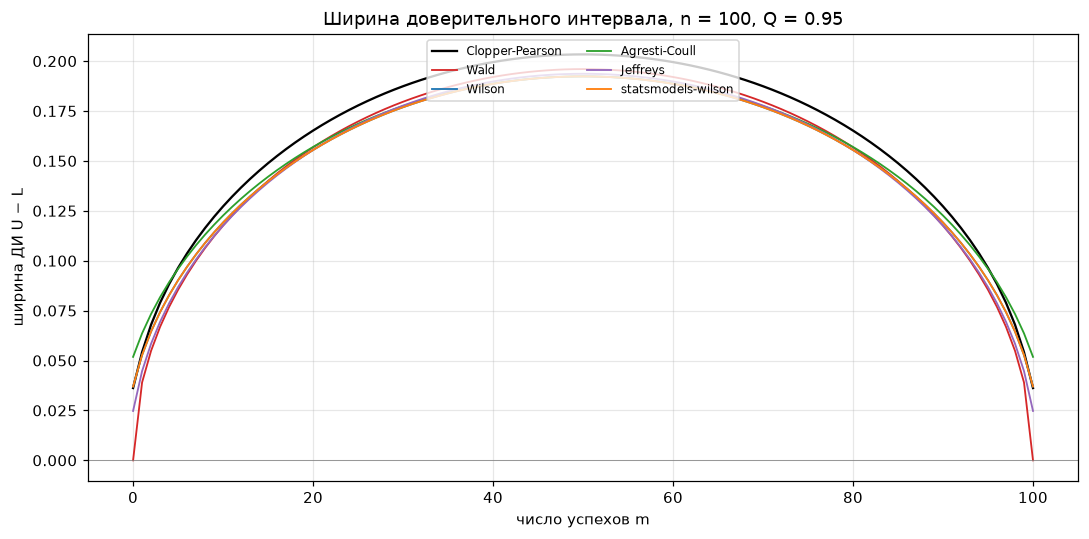

Clopper-Pearson: W(m=0)=0.0362, W(m=50)=0.2034, W(m=100)=0.0362, max W=0.2034 at m=50
Wald: W(m=0)=0.0000, W(m=50)=0.1960, W(m=100)=0.0000, max W=0.1960 at m=50
Wilson: W(m=0)=0.0370, W(m=50)=0.1923, W(m=100)=0.0370, max W=0.1923 at m=50


In [4]:
n_plot = 100
m_vals = np.arange(n_plot + 1)
widths = {meth: np.zeros(n_plot + 1) for meth in METHODS if meth != 'statsmodels-wilson'}
widths['statsmodels-wilson'] = np.zeros(n_plot + 1)

for m in m_vals:
    for meth in METHODS:
        lo, hi = ci_pair(n_plot, m, meth)
        widths[meth][m] = hi - lo

fig, ax = plt.subplots(figsize=(10, 5))
for meth in METHODS:
    ax.plot(m_vals, widths[meth], label=meth, color=COLORS[meth], lw=1.5 if meth == 'Clopper-Pearson' else 1.2)
ax.axhline(0, color='gray', lw=0.5)
ax.set(xlabel='число успехов m', ylabel='ширина ДИ U − L', title=f'Ширина доверительного интервала, n = {n_plot}, Q = {Q}')
ax.legend(fontsize=8, loc='upper center', ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Краткая численная сводка
for meth in ['Clopper-Pearson', 'Wald', 'Wilson']:
    W = widths[meth]
    print(f"{meth}: W(m=0)={W[0]:.4f}, W(m=50)={W[50]:.4f}, W(m=100)={W[100]:.4f}, max W={W.max():.4f} at m={W.argmax()}")


## 3. Эмпирическое покрытие $Q^*$ в зависимости от $n$

Для каждого метода, $p$ и $n$ симулируем $N = 10^3$ выборок. Внутри цикла для CP используем быстрые бета-квантили. На графиках — отдельные панели для $p \in \{0{,}1, 0{,}5, 0{,}9\}$; пунктир — номинальное $Q = 0{,}95$; закрашенная полоса — точный CP-интервал для доли накрытий (мета-ДИ для $Q^*$).


In [5]:
def cp_coverage_band(k, n_trials=N_SIM, alpha=ALPHA):
    """CP (90% при alpha=0.05) для истинной доли k/n_trials."""
    return clopper_pearson_beta(n_trials, k, alpha)


def simulate_coverage(n, p_true, method, n_trials=N_SIM):
    m_samples = rng.binomial(n, p_true, size=n_trials)
    covered = np.zeros(n_trials, dtype=bool)
    for i, m in enumerate(m_samples):
        lo, hi = ci_pair(n, int(m), method)
        covered[i] = lo < p_true < hi
    k = covered.sum()
    q_star = k / n_trials
    lo_q, hi_q = cp_coverage_band(k, n_trials)
    return q_star, lo_q, hi_q


ns = [10, 50, 100, 150, 200, 500]
ps = [0.1, 0.5, 0.9]
methods_cov = [m for m in METHODS if m != 'statsmodels-wilson']

results = {}
for p in ps:
    results[p] = {meth: {'n': [], 'q': [], 'q_lo': [], 'q_hi': []} for meth in methods_cov}
    for n in ns:
        for meth in methods_cov:
            q_star, q_lo, q_hi = simulate_coverage(n, p, meth)
            results[p][meth]['n'].append(n)
            results[p][meth]['q'].append(q_star)
            results[p][meth]['q_lo'].append(q_lo)
            results[p][meth]['q_hi'].append(q_hi)


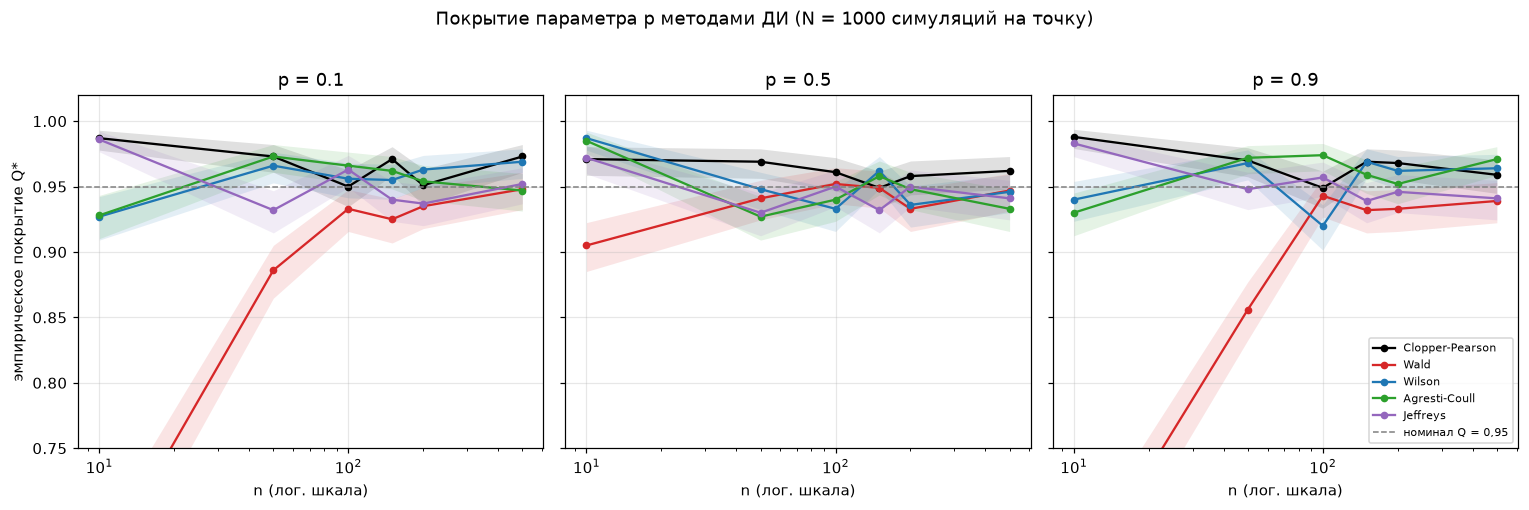

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
for ax, p in zip(axes, ps):
    for meth in methods_cov:
        d = results[p][meth]
        ns_arr = np.array(d['n'])
        q_arr = np.array(d['q'])
        q_lo = np.array(d['q_lo'])
        q_hi = np.array(d['q_hi'])
        ax.plot(ns_arr, q_arr, 'o-', label=meth, color=COLORS[meth], ms=4)
        ax.fill_between(ns_arr, q_lo, q_hi, color=COLORS[meth], alpha=0.12, linewidth=0)
    ax.axhline(Q, color='gray', ls='--', lw=1, label='номинал Q = 0,95')
    ax.set(xscale='log', xlabel='n (лог. шкала)', title=f'p = {p}')
    ax.set_ylim(0.75, 1.02)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('эмпирическое покрытие Q*')
axes[-1].legend(fontsize=7, loc='lower right')
plt.suptitle(f'Покрытие параметра p методами ДИ (N = {N_SIM} симуляций на точку)', y=1.02)
plt.tight_layout()
plt.show()


## Выводы

In [7]:
print('=== Таблица Q* (округлённо) для p = 0.1 ===')
print(f"{'n':>5}", '  '.join(f'{m:>18}' for m in methods_cov))
for n in ns:
    row = f"{n:5d}"
    for meth in methods_cov:
        q = results[0.1][meth]['q'][ns.index(n)]
        row += f" {q:18.3f}"
    print(row)

print('\n=== Систематическое занижение покрытия при p = 0.1 (Q* < 0.936 ≈ Q − 2σ) ===')
thr = Q - 1.96 * np.sqrt(Q * (1 - Q) / N_SIM)
for meth in methods_cov:
    bad = []
    for n in ns:
        q = results[0.1][meth]['q'][ns.index(n)]
        if q < thr:
            bad.append(f"n={n} (Q*={q:.3f})")
    if bad:
        print(f"  {meth}: {', '.join(bad)}")
    else:
        print(f"  {meth}: заметного недопокрытия нет (все Q* ≥ {thr:.3f})")

print('\nКачественные итоги:')
print('• Clopper–Pearson и Jeffreys дают покрытие не ниже номинала (консервативны), часто Q* > 0,95, особенно при краевых p.')
print('• Wald при p = 0,1 систематически недопокрывает (Q* заметно < 0,95 при малых и средних n).')
print('• Wilson и Agresti–Coull ближе к 0,95; Wilson обычно ровнее по разным p.')
print('• При p = 0,5 все разумные методы близки к 0,95; CP чуть шире → Q* слегка выше.')
print('• График ширины: у CP максимум у m≈0 и m≈n; Wald даёт узкие интервалы у краёв → причина недопокрытия.')


=== Таблица Q* (округлённо) для p = 0.1 ===
    n    Clopper-Pearson                Wald              Wilson       Agresti-Coull            Jeffreys
   10              0.987              0.655              0.927              0.928              0.986
   50              0.973              0.886              0.966              0.973              0.932
  100              0.950              0.933              0.956              0.966              0.963
  150              0.971              0.925              0.955              0.962              0.940
  200              0.951              0.935              0.963              0.954              0.937
  500              0.973              0.948              0.969              0.947              0.952

=== Систематическое занижение покрытия при p = 0.1 (Q* < 0.936 ≈ Q − 2σ) ===
  Clopper-Pearson: заметного недопокрытия нет (все Q* ≥ 0.936)
  Wald: n=10 (Q*=0.655), n=50 (Q*=0.886), n=100 (Q*=0.933), n=150 (Q*=0.925), n=200 (Q*=0.935)
  Wilson: